In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [2]:
DATA_PATH = r"../data/raw/cardiovascular/cardio_data_processed.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")

Dataset shape: (68205, 17)


In [3]:
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,bp_category,bp_category_encoded
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0,50,21.967120,Hypertension Stage 1,Hypertension Stage 1
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1,55,34.927679,Hypertension Stage 2,Hypertension Stage 2
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1,51,23.507805,Hypertension Stage 1,Hypertension Stage 1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1,48,28.710479,Hypertension Stage 2,Hypertension Stage 2
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0,47,23.011177,Normal,Normal


In [4]:
df.tail()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,bp_category,bp_category_encoded
68200,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0,52,26.927438,Hypertension Stage 1,Hypertension Stage 1
68201,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1,61,50.472681,Hypertension Stage 2,Hypertension Stage 2
68202,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1,52,31.353579,Hypertension Stage 2,Hypertension Stage 2
68203,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1,61,27.099251,Hypertension Stage 1,Hypertension Stage 1
68204,99999,20540,1,170,72.0,120,80,2,1,0,0,1,0,56,24.913495,Hypertension Stage 1,Hypertension Stage 1


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 68205 entries, 0 to 68204
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   68205 non-null  int64  
 1   age                  68205 non-null  int64  
 2   gender               68205 non-null  int64  
 3   height               68205 non-null  int64  
 4   weight               68205 non-null  float64
 5   ap_hi                68205 non-null  int64  
 6   ap_lo                68205 non-null  int64  
 7   cholesterol          68205 non-null  int64  
 8   gluc                 68205 non-null  int64  
 9   smoke                68205 non-null  int64  
 10  alco                 68205 non-null  int64  
 11  active               68205 non-null  int64  
 12  cardio               68205 non-null  int64  
 13  age_years            68205 non-null  int64  
 14  bmi                  68205 non-null  float64
 15  bp_category          68205 non-null  str    
 1

In [6]:
print("Columns:")

for i, column in enumerate(df.columns, start=1):
    print(f"{i:2}. {column}")

Columns:
 1. id
 2. age
 3. gender
 4. height
 5. weight
 6. ap_hi
 7. ap_lo
 8. cholesterol
 9. gluc
10. smoke
11. alco
12. active
13. cardio
14. age_years
15. bmi
16. bp_category
17. bp_category_encoded


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,68205.0,49972.410498,28852.138290,0.000000,24991.000000,50008.000000,74878.000000,99999.000000
age,68205.0,19462.667737,2468.381854,10798.000000,17656.000000,19700.000000,21323.000000,23713.000000
gender,68205.0,1.348625,0.476539,1.000000,1.000000,1.000000,2.000000,2.000000
height,68205.0,164.372861,8.176756,55.000000,159.000000,165.000000,170.000000,250.000000
weight,68205.0,74.100688,14.288862,11.000000,65.000000,72.000000,82.000000,200.000000
ap_hi,68205.0,126.434924,15.961685,90.000000,120.000000,120.000000,140.000000,180.000000
ap_lo,68205.0,81.263925,9.143985,60.000000,80.000000,80.000000,90.000000,120.000000
cholesterol,68205.0,1.363243,0.678080,1.000000,1.000000,1.000000,1.000000,3.000000
gluc,68205.0,1.225174,0.571288,1.000000,1.000000,1.000000,1.000000,3.000000
smoke,68205.0,0.087662,0.282805,0.000000,0.000000,0.000000,0.000000,1.000000


In [ ]:
missing = df.isnull().sum()

missing_summary = pd.DataFrame(
    {"missing_count": missing, "missing_percentage": (missing / len(df)) * 100}
)

missing_summary.sort_values("missing_count", ascending=False)

,missing_count,missing_percentage
id,0,0.0
age,0,0.0
gender,0,0.0
height,0,0.0
weight,0,0.0
ap_hi,0,0.0
ap_lo,0,0.0
cholesterol,0,0.0
gluc,0,0.0
smoke,0,0.0


In [9]:
duplicate_rows = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_rows}")

Duplicate rows: 0


In [10]:
duplicate_ids = df["id"].duplicated().sum()

print(f"Duplicate IDs: {duplicate_ids}")

Duplicate IDs: 0


In [11]:
target_counts = df["cardio"].value_counts().sort_index()

print(target_counts)

cardio
0    34533
1    33672
Name: count, dtype: int64


In [ ]:
target_percentages = df["cardio"].value_counts(normalize=True).sort_index().mul(100)

print(target_percentages)

cardio
0    50.631185
1    49.368815
Name: proportion, dtype: float64


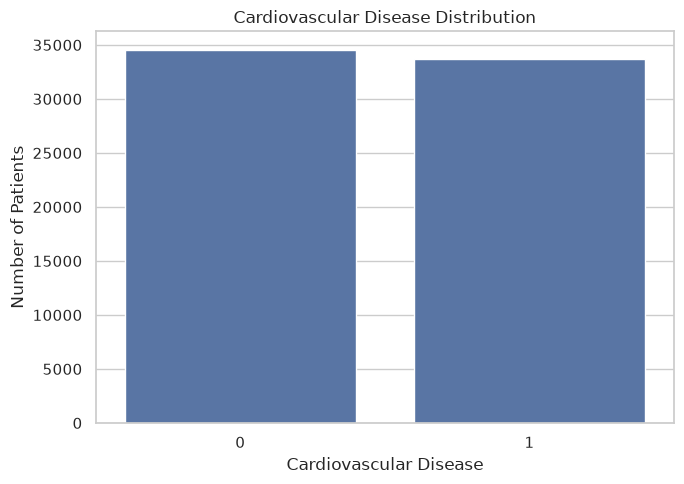

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="cardio")

plt.title("Cardiovascular Disease Distribution")
plt.xlabel("Cardiovascular Disease")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [14]:
numerical_features = ["age_years", "height", "weight", "ap_hi", "ap_lo", "bmi"]

In [15]:
df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age_years,68205.0,52.823635,6.769909,29.000000,48.000000,53.000000,58.000000,64.000000
height,68205.0,164.372861,8.176756,55.000000,159.000000,165.000000,170.000000,250.000000
weight,68205.0,74.100688,14.288862,11.000000,65.000000,72.000000,82.000000,200.000000
ap_hi,68205.0,126.434924,15.961685,90.000000,120.000000,120.000000,140.000000,180.000000
ap_lo,68205.0,81.263925,9.143985,60.000000,80.000000,80.000000,90.000000,120.000000
bmi,68205.0,27.510513,6.026497,3.471784,23.875115,26.346494,30.116213,298.666667


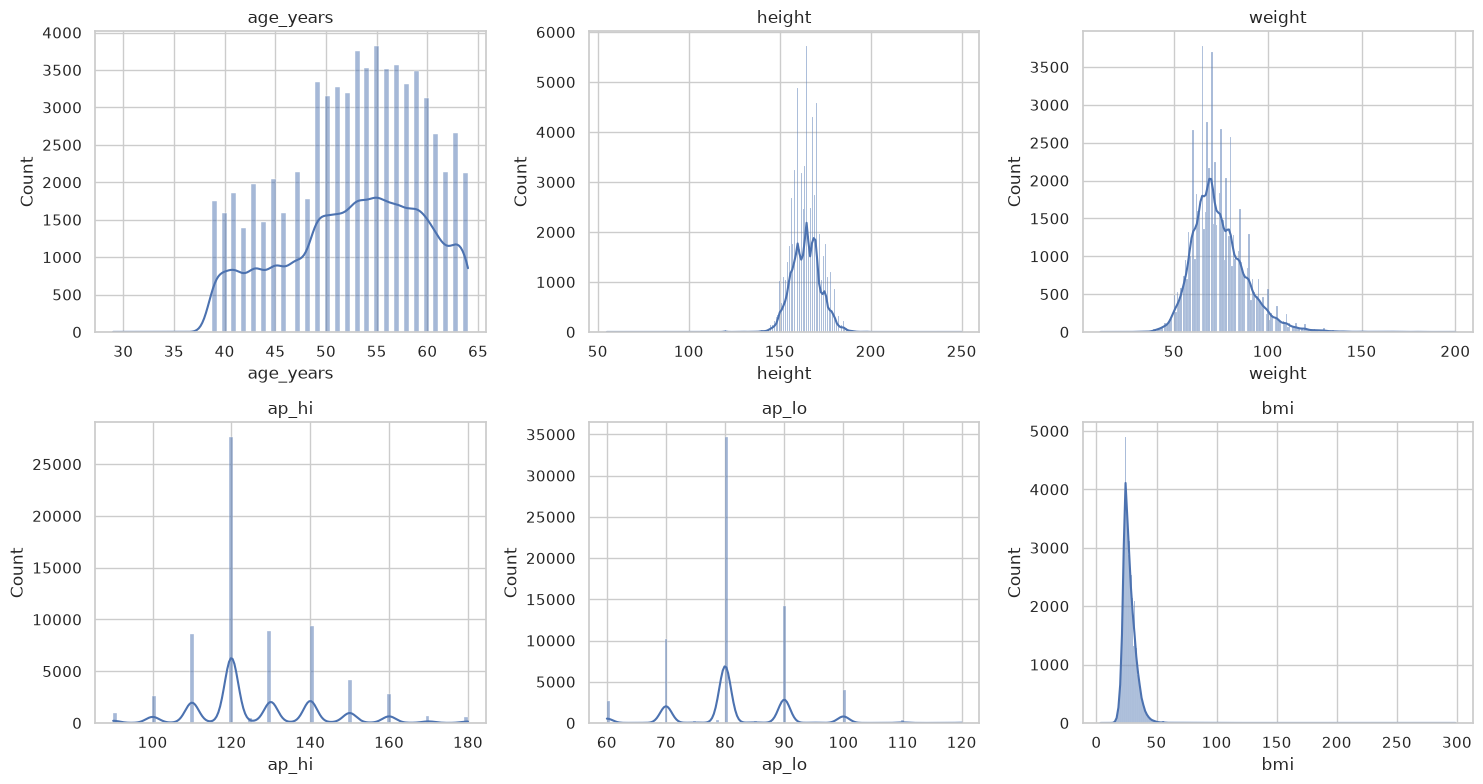

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flat, numerical_features):
    sns.histplot(data=df, x=column, kde=True, ax=ax)

    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [17]:
categorical_features = ["gender", "cholesterol", "gluc", "smoke", "alco", "active"]

In [18]:
for column in categorical_features:
    print(f"\n{'=' * 50}")
    print(column)
    print("=" * 50)
    print(df[column].value_counts().sort_index())


gender
gender
1    44427
2    23778
Name: count, dtype: int64

cholesterol
cholesterol
1    51222
2     9191
3     7792
Name: count, dtype: int64

gluc
gluc
1    58027
2     4998
3     5180
Name: count, dtype: int64

smoke
smoke
0    62226
1     5979
Name: count, dtype: int64

alco
alco
0    64581
1     3624
Name: count, dtype: int64

active
active
0    13399
1    54806
Name: count, dtype: int64


In [19]:
for column in categorical_features:
    disease_rate = df.groupby(column)["cardio"].mean().mul(100)

    print(disease_rate)
    print()

gender
1    49.145790
2    49.785516
Name: cardio, dtype: float64

cholesterol
1    43.475460
2    59.514743
3    76.142197
Name: cardio, dtype: float64

gluc
1    47.477898
2    58.623449
3    61.621622
Name: cardio, dtype: float64

smoke
0    49.625558
1    46.696772
Name: cardio, dtype: float64

alco
0    49.475852
1    47.461369
Name: cardio, dtype: float64

active
0    53.205463
1    48.430829
Name: cardio, dtype: float64



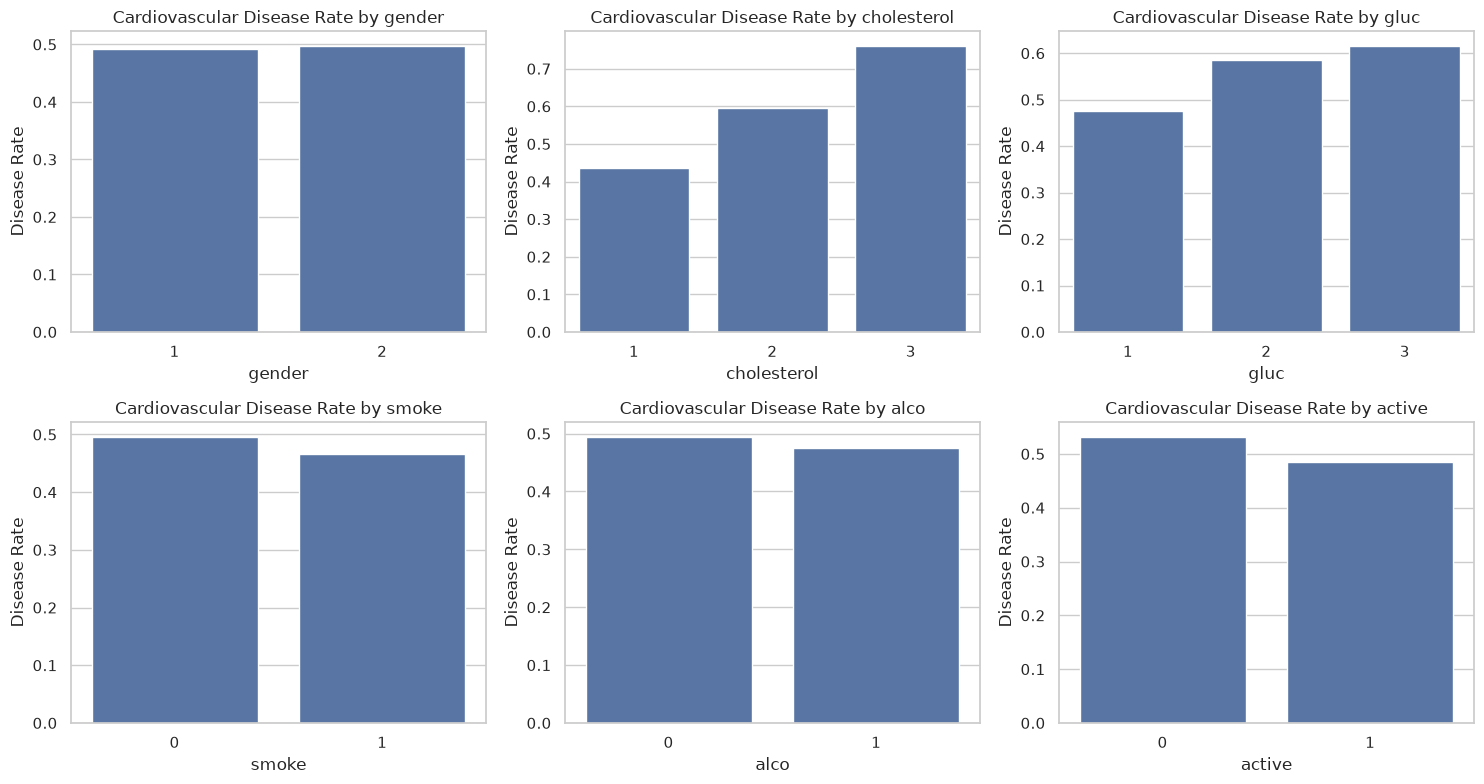

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, column in zip(axes.flat, categorical_features):
    sns.barplot(data=df, x=column, y="cardio", errorbar=None, ax=ax)

    ax.set_title(f"Cardiovascular Disease Rate by {column}")
    ax.set_ylabel("Disease Rate")
    ax.set_xlabel(column)

plt.tight_layout()
plt.show()

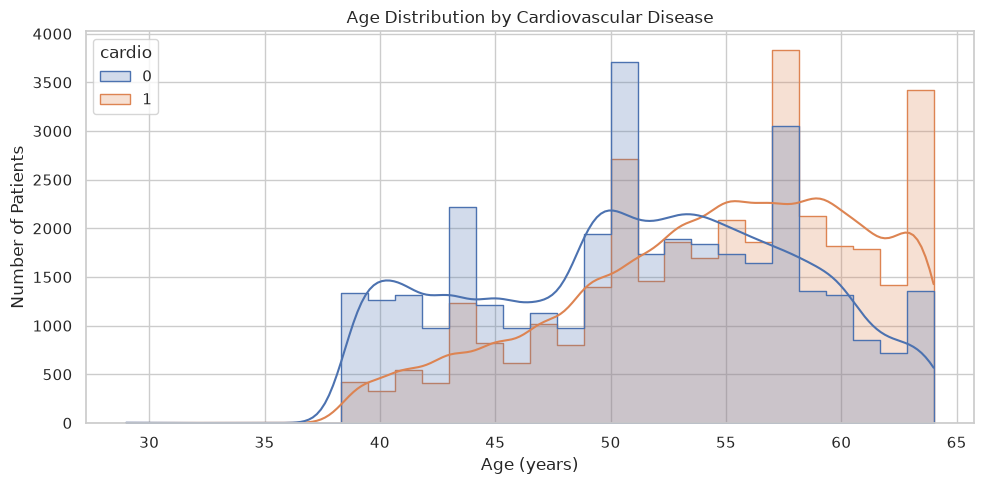

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="age_years", hue="cardio", bins=30, kde=True, element="step")

plt.title("Age Distribution by Cardiovascular Disease")
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

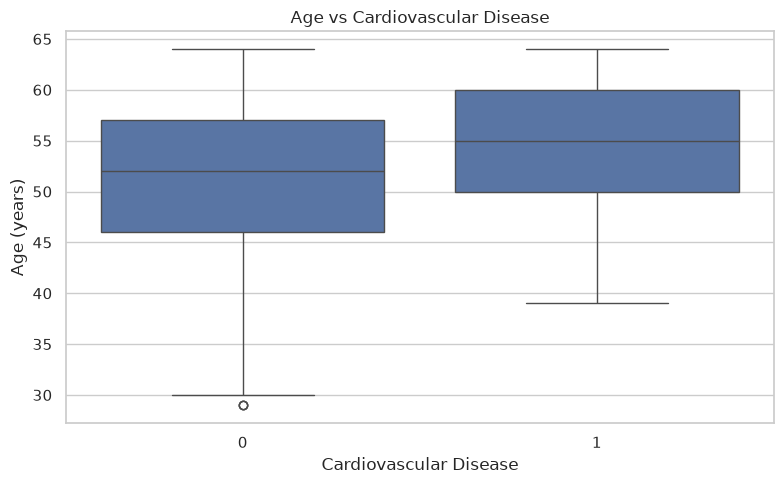

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="cardio", y="age_years")

plt.title("Age vs Cardiovascular Disease")
plt.xlabel("Cardiovascular Disease")
plt.ylabel("Age (years)")

plt.tight_layout()
plt.show()

In [23]:
df[["ap_hi", "ap_lo"]].describe().T

,count,mean,std,min,25%,50%,75%,max
ap_hi,68205.0,126.434924,15.961685,90.0,120.0,120.0,140.0,180.0
ap_lo,68205.0,81.263925,9.143985,60.0,80.0,80.0,90.0,120.0


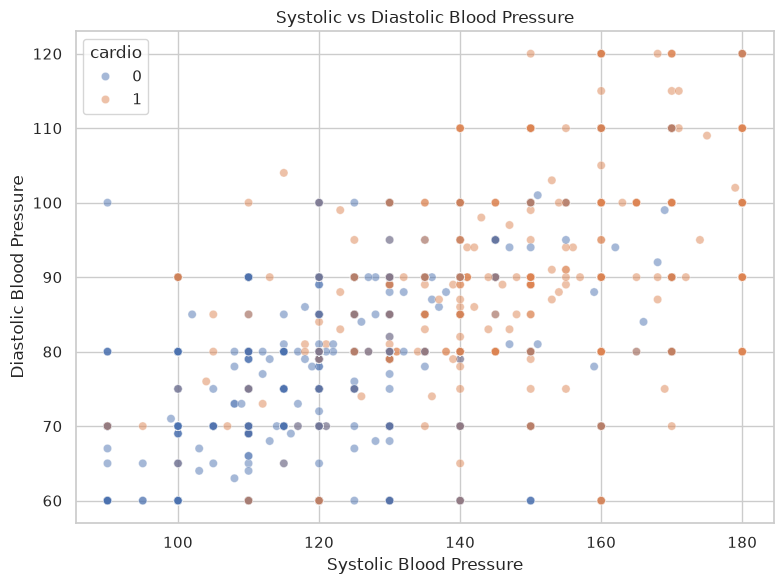

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df.sample(min(10000, len(df)), random_state=42),
    x="ap_hi",
    y="ap_lo",
    hue="cardio",
    alpha=0.5,
)

plt.title("Systolic vs Diastolic Blood Pressure")
plt.xlabel("Systolic Blood Pressure")
plt.ylabel("Diastolic Blood Pressure")

plt.tight_layout()
plt.show()

In [25]:
invalid_bp = df[
    (df["ap_hi"] <= df["ap_lo"])
    | (df["ap_hi"] < 70)
    | (df["ap_hi"] > 250)
    | (df["ap_lo"] < 40)
    | (df["ap_lo"] > 150)
]

print(f"Potentially suspicious BP records: {len(invalid_bp)}")

invalid_bp[["age_years", "ap_hi", "ap_lo", "cardio"]].head(20)

Potentially suspicious BP records: 5


,age_years,ap_hi,ap_lo,cardio
12466,43,100,100,1
22303,56,95,100,1
31366,63,100,100,0
45316,41,90,100,0
51424,57,90,120,1


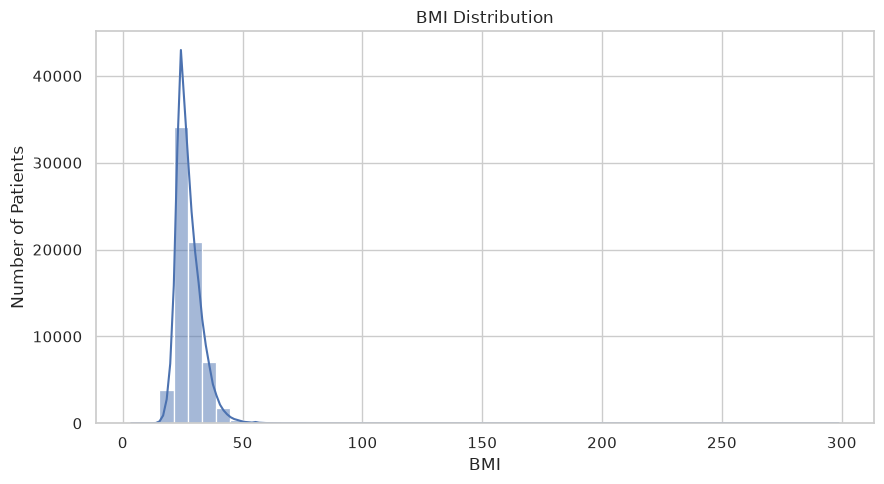

In [26]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="bmi", bins=50, kde=True)

plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [27]:
suspicious_bmi = df[(df["bmi"] < 10) | (df["bmi"] > 60)]

print(f"Suspicious BMI records: {len(suspicious_bmi)}")

suspicious_bmi[["age_years", "height", "weight", "bmi", "cardio"]].sort_values(
    "bmi"
).head(20)

Suspicious BMI records: 65


,age_years,height,weight,bmi,cardio
32945,59,178,11.0,3.471784,1
28724,55,177,22.0,7.022248,0
58644,59,162,21.0,8.001829,1
26119,63,157,23.0,9.331007,0
59138,51,171,29.0,9.917581,1
38521,40,108,70.0,60.013717,1
62993,59,169,172.0,60.221981,0
14311,57,159,153.0,60.519758,1
41357,53,160,155.0,60.546875,1
40775,56,164,164.0,60.975610,1


In [28]:
df["bmi_calculated"] = df["weight"] / (df["height"] / 100) ** 2

In [29]:
bmi_difference = (df["bmi"] - df["bmi_calculated"]).abs()

bmi_difference.describe()

count    6.820500e+04
mean     9.409574e-16
std      1.640030e-15
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      3.552714e-15
max      2.842171e-14
dtype: float64

In [30]:
print(f"Maximum BMI difference: " f"{bmi_difference.max():.6f}")

print(f"Mean BMI difference: " f"{bmi_difference.mean():.6f}")

Maximum BMI difference: 0.000000
Mean BMI difference: 0.000000


In [31]:
df[["height", "weight", "bmi", "bmi_calculated"]].assign(
    difference=bmi_difference
).sort_values("difference", ascending=False).head(20)

,height,weight,bmi,bmi_calculated,difference
51984,67,80.0,178.213411,178.213411,2.842171e-14
23300,81,156.0,237.768633,237.768633,2.842171e-14
13965,67,57.0,126.977055,126.977055,1.421085e-14
5992,122,161.0,108.169847,108.169847,1.421085e-14
10795,159,103.0,40.742059,40.742059,7.105427e-15
25489,165,105.0,38.567493,38.567493,7.105427e-15
7011,165,136.0,49.954086,49.954086,7.105427e-15
8458,119,89.0,62.848669,62.848669,7.105427e-15
56375,165,105.0,38.567493,38.567493,7.105427e-15
12672,151,78.0,34.209026,34.209026,7.105427e-15


In [ ]:
correlation_features = [
    "age_years",
    "height",
    "weight",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    "cardio",
]

correlation_matrix = df[correlation_features].corr()

correlation_matrix

,age_years,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
age_years,1.000000,-0.081974,0.053199,0.211314,0.155777,0.154738,0.098212,-0.048089,-0.029052,-0.010385,0.238875
height,-0.081974,1.000000,0.292679,0.018544,0.035550,-0.050957,-0.019317,0.187543,0.094354,-0.008241,-0.011276
weight,0.053199,0.292679,1.000000,0.268289,0.250184,0.139816,0.105734,0.067169,0.067177,-0.017443,0.177829
ap_hi,0.211314,0.018544,0.268289,1.000000,0.731812,0.195330,0.093151,0.026032,0.032536,-0.001409,0.433802
ap_lo,0.155777,0.035550,0.250184,0.731812,1.000000,0.161637,0.073319,0.023836,0.036212,-0.001234,0.342900
cholesterol,0.154738,-0.050957,0.139816,0.195330,0.161637,1.000000,0.450452,0.009570,0.034184,0.008658,0.220778
gluc,0.098212,-0.019317,0.105734,0.093151,0.073319,0.450452,1.000000,-0.006109,0.009379,-0.008003,0.088905
smoke,-0.048089,0.187543,0.067169,0.026032,0.023836,0.009570,-0.006109,1.000000,0.338226,0.024999,-0.016567
alco,-0.029052,0.094354,0.067177,0.032536,0.036212,0.034184,0.009379,0.338226,1.000000,0.024339,-0.009038
active,-0.010385,-0.008241,-0.017443,-0.001409,-0.001234,0.008658,-0.008003,0.024999,0.024339,1.000000,-0.037944


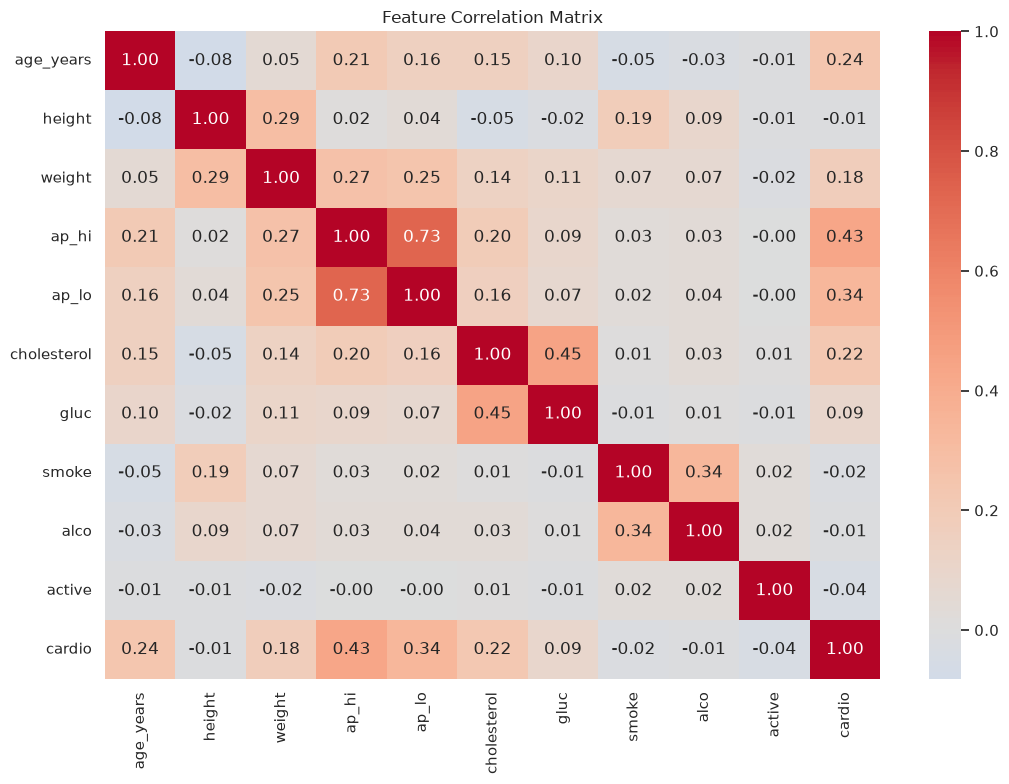

In [33]:
plt.figure(figsize=(11, 8))

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)

plt.title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [34]:
target_correlation = (
    correlation_matrix["cardio"].drop("cardio").sort_values(ascending=False)
)

target_correlation

ap_hi          0.433802
ap_lo          0.342900
age_years      0.238875
cholesterol    0.220778
weight         0.177829
gluc           0.088905
alco          -0.009038
height        -0.011276
smoke         -0.016567
active        -0.037944
Name: cardio, dtype: float64

In [35]:
print(df["bp_category"].value_counts())

bp_category
Hypertension Stage 1    39750
Hypertension Stage 2    15937
Normal                   9417
Elevated                 3101
Name: count, dtype: int64


In [36]:
print(df["bp_category"].value_counts(normalize=True).mul(100))

bp_category
Hypertension Stage 1    58.280185
Hypertension Stage 2    23.366322
Normal                  13.806906
Elevated                 4.546587
Name: proportion, dtype: float64


In [37]:
bp_disease_rate = (
    df.groupby("bp_category")["cardio"].mean().mul(100).sort_values(ascending=False)
)

bp_disease_rate

bp_category
Hypertension Stage 2    80.071532
Hypertension Stage 1    44.837736
Elevated                32.279910
Normal                  22.162047
Name: cardio, dtype: float64

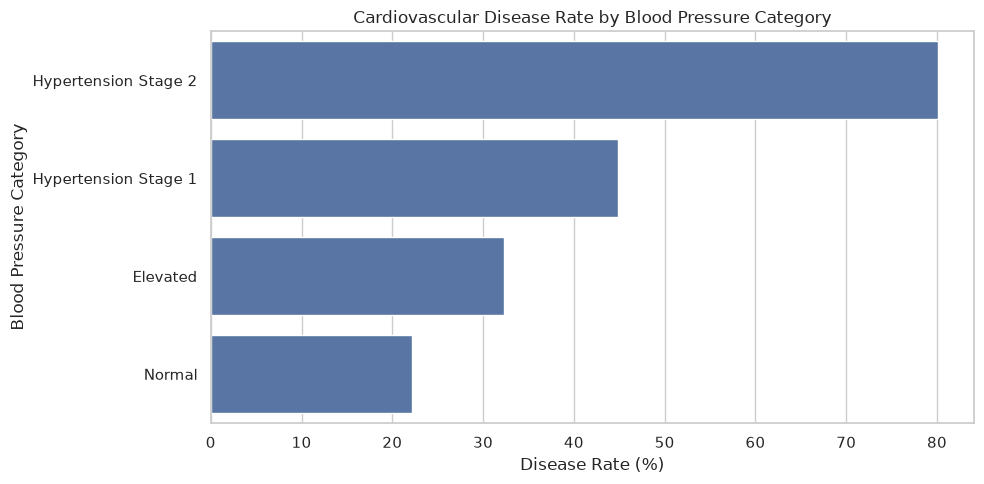

In [38]:
plt.figure(figsize=(10, 5))

sns.barplot(x=bp_disease_rate.values, y=bp_disease_rate.index)

plt.title("Cardiovascular Disease Rate by Blood Pressure Category")
plt.xlabel("Disease Rate (%)")
plt.ylabel("Blood Pressure Category")

plt.tight_layout()
plt.show()

In [39]:
df.columns.tolist()

['id',
 'age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio',
 'age_years',
 'bmi',
 'bp_category',
 'bp_category_encoded',
 'bmi_calculated']

In [40]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["id"].duplicated().sum())
print("Target distribution:")
print(df["cardio"].value_counts())

Dataset shape: (68205, 18)
Missing values: 0
Duplicate rows: 0
Duplicate IDs: 0
Target distribution:
cardio
0    34533
1    33672
Name: count, dtype: int64


In [41]:
df.drop(columns=["bmi_calculated"], inplace=True)